# Density estimation with HAL on simulated data

This tutorial fits the HAL density estimator (HAL-MLE) to a sample from a known density and compares the fit
with the truth. It uses the package's defaults: order k = 2, the L1 bound M chosen by 5-fold cross-validation
on the exact held-out log-likelihood, and a final fit whose basis passed the optimality check (the cleaned
basis).

The estimators work on [0, 1]. Rescale your data by bounds fixed in advance (not by the sample's minimum and
maximum) before fitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

from haldensity.datasets import TruncatedGMM
from haldensity.full_uni import OptunaHyperparameterTuner

truth = TruncatedGMM(
    components=[{"mean": 0.35, "std": 0.1, "lower": 0.0, "upper": 1.0},
                {"mean": 0.65, "std": 0.05, "lower": 0.0, "upper": 1.0}],
    weights=[0.6, 0.4],
)
np.random.seed(0)
data = pd.DataFrame({"W1": truth.generate_samples(400)})
data.describe().T

,count,mean,std,min,25%,50%,75%,max
W1,400.0,0.471056,0.16972,0.091909,0.331823,0.445431,0.634113,0.754654


## Choosing the L1 bound M by cross-validation

`OptunaHyperparameterTuner` searches M on a log scale and scores each candidate by the exact held-out
log-likelihood. `fit_best_model()` refits at the chosen M on all the data. The order stays at the package
default, k = 2; `param_overrides={"basis_order": [0, 1, 2]}` would cross-validate it as well.

In [2]:
tuner = OptunaHyperparameterTuner("CVXPYEstimator", data, random_state=0, silent=True, show_progress=False)
search = tuner.optimize(n_trials=30, show_progress=False)
est = tuner.fit_best_model()
print(f"chosen M = {tuner.best_params['norm_constraint']:.4g} at order k = {est.basis_order}")
print(f"held-out log-likelihood per observation: {search['best_metric_value']:.4f}")

chosen M = 4039 at order k = 2
held-out log-likelihood per observation: 0.5461


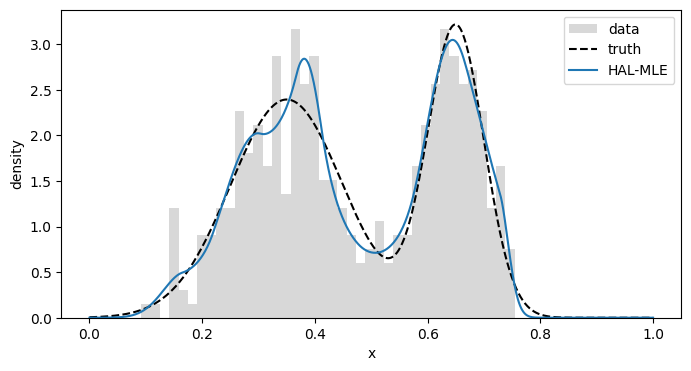

integrated squared error: 0.0279


In [3]:
x = np.linspace(0, 1, 1001)
fitted, true = est.get_density_at_points(x), truth.compute_density(x)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data["W1"], bins=40, density=True, alpha=0.3, color="grey", label="data")
ax.plot(x, true, "k--", label="truth")
ax.plot(x, fitted, color="C0", label="HAL-MLE")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

print(f"integrated squared error: {trapezoid((fitted - true) ** 2, x):.4f}")

## Diagnostics

Every fit records what it did:

* `certified`: the final solve passed the optimality check, so its basis is the cleaned basis used for
  standard errors (if the check fails, the package gives the point estimate but no SE);
* `log_z_gap`: the accurate log normalizer minus the one inside the fitting objective. It is near 0 when the
  fitting grid sees all of the fitted mass; above 0.01 nats the fit warns and suggests a larger
  `n_grid_points` (this happens when the data occupy a small part of [0, 1]);
* `n_selected_knots`: the number of knots with a nonzero coefficient. With a bound this large nearly every
  knot is used; the L1 bound M, not the number of knots, controls how rough the fit can be;
* `solver_used`: the solver of the final fit (MOSEK when it is installed, otherwise the first fallback that
  succeeds).

In [4]:
results = est.get_results()
{key: results[key] for key in ("certified", "log_z_gap", "n_selected_knots", "solver_used")}

{'certified': True,
 'log_z_gap': 2.3920060723270353e-06,
 'n_selected_knots': 399,
 'solver_used': 'MOSEK'}